# 02 - Simulation des modèles SV

Simulation des modèles `StochVol` et `StochVolLeverage` et `StochVolLeverageJump` de la bibliothèque `particles`, avec les équations telles qu'implémentées dans le code.

### Simulation du modèle SV (notation `particles`)

Modèle `StochVol` tel qu'implémenté dans le code :

$$
\begin{aligned}
y_t &= \epsilon_t \, \exp(h_t/2), \qquad \epsilon_t \sim \mathcal{N}(0,1) \\
h_{t+1} &= \mu(1-\rho) + \rho\, h_t + \sigma\, \eta_t, \qquad \eta_t \sim \mathcal{N}(0,1), \quad t = 1, \dots, T \\
h_0 &\sim \mathcal{N}\!\left(\mu,\ \frac{\sigma^2}{1-\rho^2}\right)
\end{aligned}
$$

Valeurs par défaut (Pitt & Shephard, 1999) : $\mu=-1.02,\ \rho=0.9702,\ \sigma=0.178$.

In [33]:
import warnings; warnings.simplefilter('ignore')  # hide warnings

# standard libraries
from matplotlib import pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
import particles


In [ ]:
from particles import state_space_models as ssm
from particles.collectors import Moments
from sv_pf.resampling import ContinuousSMC

# ===================== 1. Simulation =====================
np.random.seed(0)
sv_model = ssm.StochVol(mu=-1., rho=.9, sigma=.1)
true_states, data = sv_model.simulate(300)
x = np.array(true_states).ravel()      # vraie log-vol x_t
y = np.array(data).ravel()             # rendements observés

N = 300
u = (np.arange(N) + 0.5) / N           # uniformes triés fixés (pour le continu)

# ===================== 2a. Bootstrap STANDARD =====================
np.random.seed(0)
alg_std = particles.SMC(fk=ssm.Bootstrap(ssm=sv_model, data=y),
                        N=N, ESSrmin=1.0, collect=[Moments()])   # resample à chaque pas
alg_std.run()
filt_std = np.array([m['mean'] for m in alg_std.summaries.moments])

# ===================== 2b. Bootstrap + resampling CONTINU =====================
np.random.seed(0)
alg_cont = ContinuousSMC(fk=ssm.Bootstrap(ssm=sv_model, data=y),
                         N=N, cont_u=u, collect=[Moments()])
alg_cont.run()
filt_cont = np.array([m['mean'] for m in alg_cont.summaries.moments])

# ===================== 3. Figure =====================
plt.style.use("ggplot")
fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

ax[0].plot(y, color="crimson")                       # données observées
ax[0].set_ylabel("rendement $y_t$")

ax[1].plot(np.exp(x/2),         color="steelblue", lw=1.3, label="vraie")
ax[1].plot(np.exp(filt_std/2),  color="crimson",   lw=1.0, label="filtrée (bootstrap std)")
ax[1].plot(np.exp(filt_cont/2), color="seagreen",  lw=1.0, ls="--", label="filtrée (bootstrap + continu)")
ax[1].set_ylabel(r"volatilité $e^{x_t/2}$"); ax[1].legend(fontsize=8)

ax[2].plot(alg_std.summaries.ESSs,  color="crimson",  lw=.8, label="ESS std")
ax[2].plot(alg_cont.summaries.ESSs, color="seagreen", lw=.8, label="ESS continu")
ax[2].axhline(N, color="gray", ls="--", lw=.7)       # N = ESS maximum
ax[2].set_ylabel("ESS"); ax[2].set_xlabel("t"); ax[2].legend(fontsize=8)

plt.tight_layout(); plt.show()

NameError: name 'ContinuousSMC' is not defined

### Modèle SVL Shifted (notation `particles`)

$$
\begin{aligned}
y_t &= \epsilon_t \, e^{h_t/2} \\
h_{t+1} &= \mu(1-\rho) + \rho\, h_t + \sigma\, \eta_t, \qquad h_1 \sim \mathcal{N}\!\left(\mu,\ \tfrac{\sigma^2}{1-\rho^2}\right)
\end{aligned}
\qquad
\begin{pmatrix} \epsilon_t \\ \eta_t \end{pmatrix} \overset{\text{i.i.d.}}{\sim} \mathcal{N}\!\left(\begin{pmatrix} 0 \\ 0 \end{pmatrix},\ \begin{pmatrix} 1 & \phi \\ \phi & 1 \end{pmatrix}\right)
$$

Décomposition : $\eta_t = \phi\,\epsilon_t + \sqrt{1-\phi^2}\,\xi_t$, avec $\xi_t \overset{\text{i.i.d.}}{\sim} \mathcal{N}(0,1)$, d'où

$$
h_{t+1} = \mu(1-\rho) + \rho\, h_t + \sigma\phi\,\epsilon_t + \sigma\sqrt{1-\phi^2}\,\xi_t .
$$

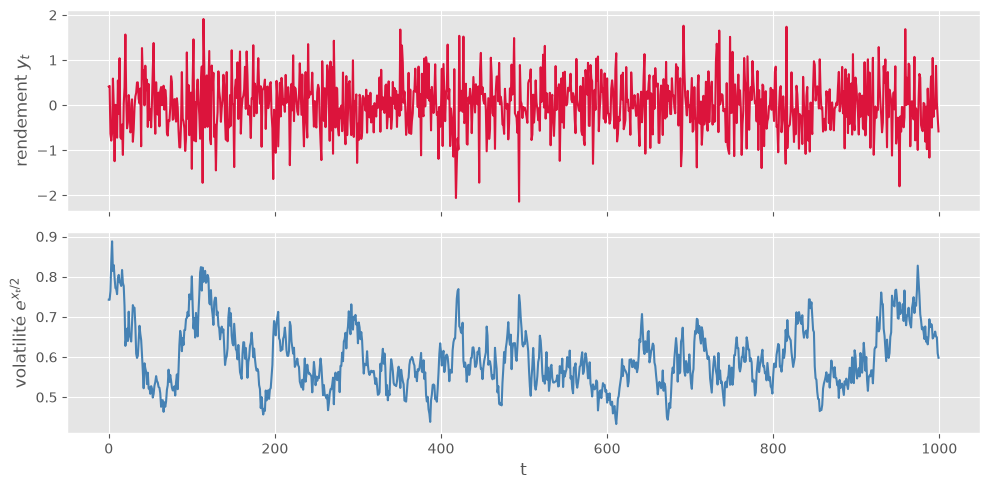

In [16]:
from sv_pf.volatility_models import StochVolLeverageShifted   # notre classe (timing papier)

# rho = persistance (phi du papier), phi = levier (rho du papier)
sv_model = StochVolLeverageShifted(mu=-1., rho=.9, sigma=.1, phi=-.5)

np.random.seed(0)
true_states, data = sv_model.simulate(1000)
x = np.array(true_states).ravel(); y = np.array(data).ravel()

plt.style.use('ggplot')
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(y, color="crimson")                    # rendement en rouge
ax[0].set_ylabel("rendement $y_t$")
ax[1].plot(np.exp(x/2), color="steelblue")        # volatilité en bleu
ax[1].set_ylabel(r"volatilité $e^{x_t/2}$")
ax[1].set_xlabel("t")
plt.tight_layout(); plt.show()

### Modèle SVLJ Shifted (notation `particles`)

$$
\begin{aligned}
y_t &= \epsilon_t \, e^{h_t/2} + J_t\,\varpi_t \\
h_{t+1} &= \mu(1-\rho) + \rho\, h_t + \sigma\, \eta_t, \qquad h_1 \sim \mathcal{N}\!\left(\mu,\ \tfrac{\sigma^2}{1-\rho^2}\right)
\end{aligned}
\qquad
\begin{pmatrix} \epsilon_t \\ \eta_t \end{pmatrix} \overset{\text{i.i.d.}}{\sim} \mathcal{N}\!\left(\mathbf{0},\ \begin{pmatrix} 1 & \phi \\ \phi & 1 \end{pmatrix}\right),
\quad J_t \sim \mathrm{Bernoulli}(\kappa),\ \varpi_t \sim \mathcal{N}(0,\sigma_J^2)
$$

Densité d'observation ($s = e^{h_t/2}$, $u_t = \tfrac{h_{t+1}-\mu-\rho(h_t-\mu)}{\sigma}$), mélange sur le saut :

$$
p(y_t \mid h_t, h_{t+1}) =
(1-\kappa)\,\mathcal{N}\!\big(s\phi u_t,\ s^2(1-\phi^2)\big)
+ \kappa\,\mathcal{N}\!\big(s\phi u_t,\ s^2(1-\phi^2) + \sigma_J^2\big).

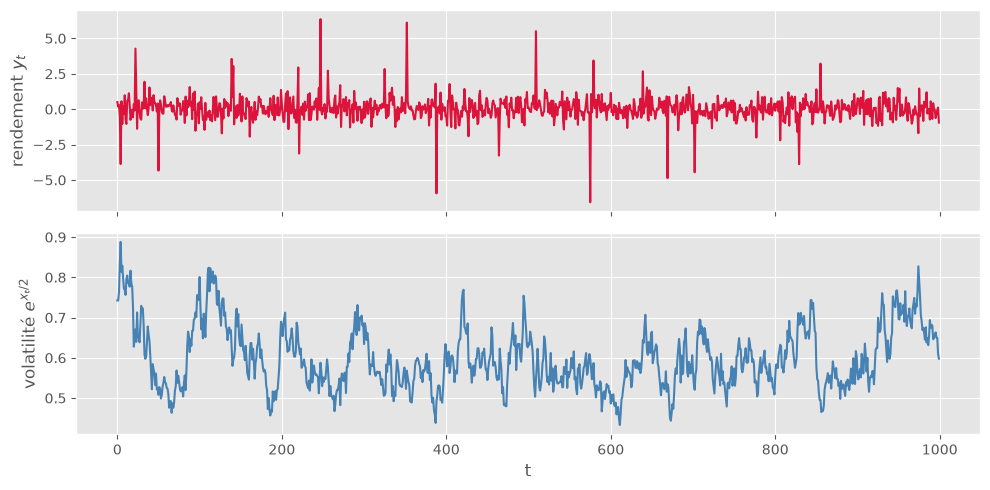

In [17]:
from sv_pf.volatility_models import StochVolLeverageJump  # SVL + sauts (timing papier)

# rho = persistance, phi = levier, kappa = proba de saut, sigma_J = taille du saut
sv_model = StochVolLeverageJump(mu=-1., rho=.9, sigma=.1, phi=-.5, kappa=.05, sigma_J=3.)

np.random.seed(0)
true_states, data = sv_model.simulate(1000)
x = np.array(true_states).ravel(); y = np.array(data).ravel()

plt.style.use('ggplot')
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(y, color="crimson")                    # rendement en rouge
ax[0].set_ylabel("rendement $y_t$")
ax[1].plot(np.exp(x/2), color="steelblue")        # volatilité en bleu
ax[1].set_ylabel(r"volatilité $e^{x_t/2}$")
ax[1].set_xlabel("t")
plt.tight_layout(); plt.show()

Interprétation : Les pics du SVLJ simule les Krach boursiers